
# Predictive Maintenance Using CRISP-DM

**CMPE 255 — Data Mining Process Assignment**

## 1. Business Understanding

### 1.1 Business Problem
Unexpected machine failures can interrupt manufacturing operations, increase maintenance costs, and reduce productivity.

This project explores whether machine operating measurements can help identify possible failure conditions and support maintenance inspection decisions.

### 1.2 Business Objective
The objective is to support maintenance teams by identifying machines that may need further inspection.

The model is intended to provide an additional warning signal rather than replace human inspection or existing safety systems.

### 1.3 Data Mining Objective
Build a binary classification model to identify machine failure conditions (0 = No Failure, 1 = Failure) using temperature, rotational speed, torque, tool wear, and product type.

Compare Logistic Regression and Random Forest, and examine how classification thresholds affect failure detection and false alarms.

### 1.4 Success Criteria
The project will be evaluated using the following criteria:

**Technical criteria**
- Compare at least two classification models.
- Evaluate precision, recall, F1-score, ROC-AUC, and confusion matrices.
- Examine the trade-off between missed failures and false alarms.
- Select a classification threshold using training cross-validation results.
- Evaluate the selected model on a separate test set.

**Business considerations**
- A useful warning system should detect failures while keeping false alarms manageable.
- Missed failures may lead to downtime, while false alarms may cause unnecessary inspections.
- Since actual maintenance costs are unavailable, the project cannot define a financially optimal threshold.

### 1.5 Constraints and Limitations
- The AI4I 2020 dataset is synthetic and does not represent measurements collected from a specific factory.
- The target describes a machine failure condition in the dataset, not the time remaining until a future failure.
- The project does not include time-series forecasting or remaining useful life estimation.
- Results from this dataset cannot establish performance in real industrial environments.
- Additional validation and operational cost analysis would be required before deployment.



### 1.6 Maintenance Decision and Practical Requirements

The model is designed to support decisions about which machines may need additional inspection.

A failure alert should be treated as a signal for further investigation, not as proof that a machine has failed.

Before using this approach in an actual factory, the maintenance team would need to define:

- The cost of missing a machine failure.
- The cost of inspecting a machine after a false alarm.
- The number of alerts the maintenance team can reasonably handle.
- The acceptable balance between missed failures and false alarms.

In this educational project, these operational requirements are unavailable.

Therefore, the classification threshold is selected using F1-score on training cross-validation predictions rather than actual maintenance costs.

The selected threshold of 0.2 is used only for the demonstration and is not claimed to be financially optimal.


In [1]:

# 2. Data Understanding - Load Dataset

import pandas as pd
import io
import zipfile
import urllib.request

# Official UCI AI4I 2020 dataset download
dataset_url = (
    "https://archive.ics.uci.edu/static/public/601/"
    "ai4i+2020+predictive+maintenance+dataset.zip"
)

# Download and read the CSV directly from the ZIP file.
with urllib.request.urlopen(dataset_url) as response:
    zip_data = response.read()

with zipfile.ZipFile(io.BytesIO(zip_data)) as archive:
    with archive.open("ai4i2020.csv") as csv_file:
        df = pd.read_csv(csv_file)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:

# 2. Data Understanding - Dataset Overview

print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nColumn names and data types:")
for column in df.columns:
    print(f"- {column}: {df[column].dtype}")

print("\nMissing values:")
missing = df.isnull().sum()
print(missing.to_string())

print("\nMachine failure distribution:")
print(df["Machine failure"].value_counts().to_string())


Total rows: 10000
Total columns: 14

Column names and data types:
- UDI: int64
- Product ID: object
- Type: object
- Air temperature [K]: float64
- Process temperature [K]: float64
- Rotational speed [rpm]: int64
- Torque [Nm]: float64
- Tool wear [min]: int64
- Machine failure: int64
- TWF: int64
- HDF: int64
- PWF: int64
- OSF: int64
- RNF: int64

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0

Machine failure distribution:
Machine failure
0    9661
1     339


In [3]:

# 2. Data Understanding - Sensor Statistics

sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

print("Sensor statistics:")
stats = df[sensor_columns].describe().T

display(stats.round(2))

print("\nProduct type distribution:")
print(df["Type"].value_counts().to_string())

print("\nDuplicate rows:", df.duplicated().sum())


Sensor statistics:


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0



Product type distribution:
Type
L    6000
M    2997
H    1003

Duplicate rows: 0


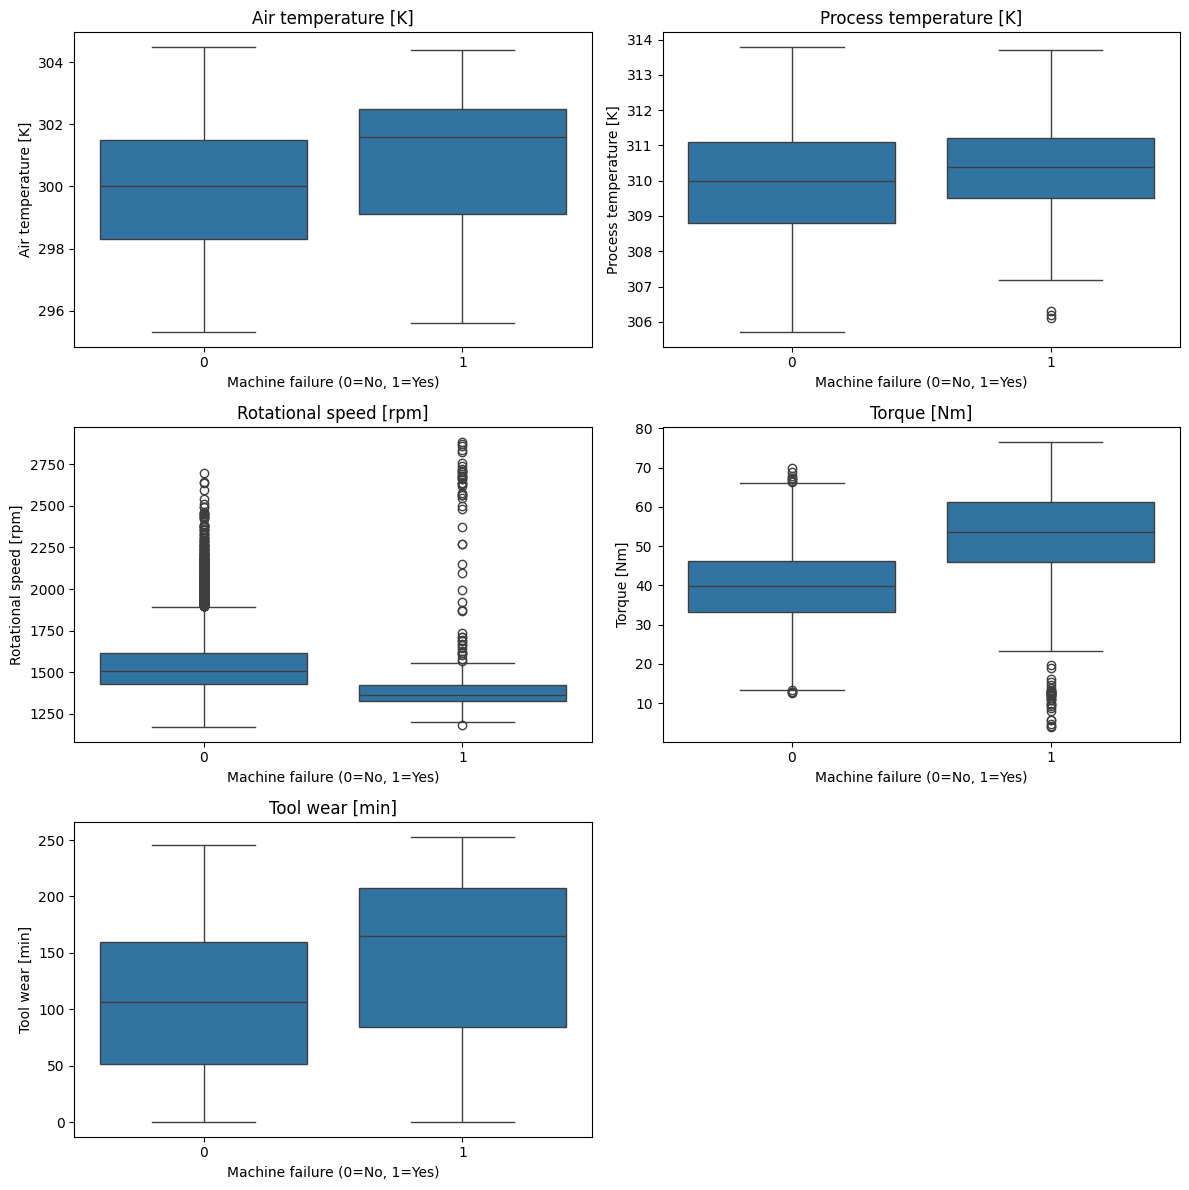

In [4]:

# 2. Data Understanding - Sensor Distributions

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("artifacts/figures", exist_ok=True)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        ax=axes[i]
    )
    axes[i].set_title(column)
    axes[i].set_xlabel("Machine failure (0=No, 1=Yes)")

fig.delaxes(axes[-1])

plt.tight_layout()
plt.savefig(
    "artifacts/figures/sensor_failure_boxplots.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()



### Initial Findings from Sensor Distributions

The boxplots compare sensor measurements between normal and failed machines.

- Failed machines generally show higher torque and tool wear.
- Failed machines have a lower median rotational speed, although some failures also occur at high speeds.
- Air temperature is slightly higher in the failure group.
- Process temperature shows substantial overlap between the two groups.

These observations suggest possible relationships between operating conditions and machine failure. However, they do not establish causation or prove which features will be most useful for prediction.

Further analysis and model evaluation are needed.


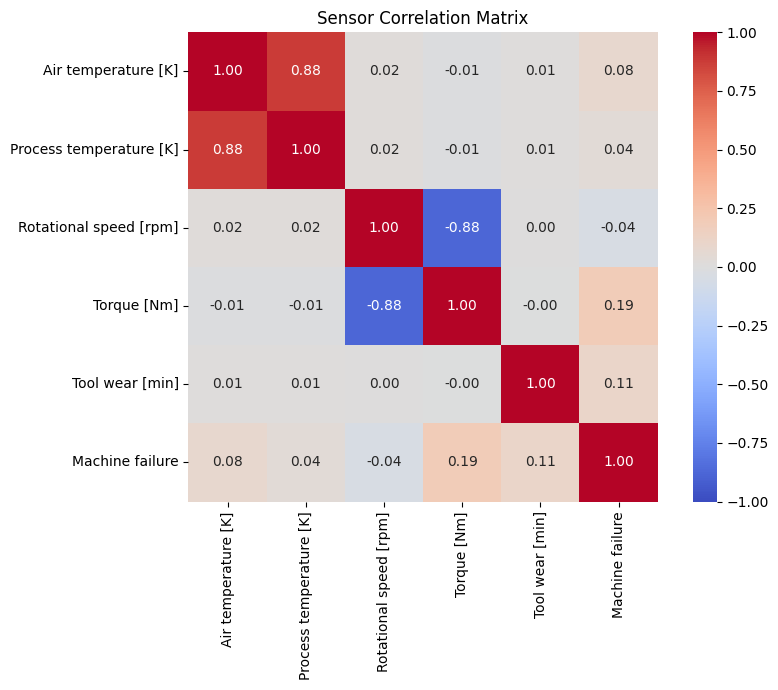


Correlation with machine failure:
Torque [Nm]                0.191
Tool wear [min]            0.105
Air temperature [K]        0.083
Process temperature [K]    0.036
Rotational speed [rpm]    -0.044


In [5]:

# 2. Data Understanding - Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

feature_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target_column = "Machine failure"

# Analyze only the planned numeric predictors and target.
corr_columns = feature_columns + [target_column]
corr_matrix = df[corr_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Sensor Correlation Matrix")
plt.tight_layout()

plt.savefig(
    "artifacts/figures/sensor_correlation.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nCorrelation with machine failure:")
print(
    corr_matrix[target_column]
    .drop(target_column)
    .sort_values(ascending=False)
    .round(3)
    .to_string()
)



### Correlation Analysis Findings

- Air temperature and process temperature show a strong positive correlation (0.88).
- Rotational speed and torque show a strong negative correlation (-0.88).
- Torque has the highest positive linear correlation with machine failure (0.191).
- Tool wear has a weaker positive correlation with failure (0.105).
- Individual correlations with machine failure are relatively weak.

These results suggest that relationships between multiple operating conditions may be more useful than individual linear correlations.

Correlation does not establish causation, and model evaluation is needed to determine predictive usefulness.


In [6]:

# 2. Data Understanding - Additional Quality Checks

# Check duplicate operating records without identifiers.
operating_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

duplicate_count = df.duplicated(
    subset=operating_columns
).sum()

print("Duplicate operating records:", duplicate_count)

# Compare machine failure rates by product type.
type_summary = df.groupby("Type")["Machine failure"].agg(
    total="count",
    failures="sum",
    failure_rate="mean"
)

type_summary["failure_rate"] *= 100

print("\nMachine failure by product type:")
print(type_summary.round(2).to_string())


Duplicate operating records: 0

Machine failure by product type:
      total  failures  failure_rate
Type                               
H      1003        21          2.09
L      6000       235          3.92
M      2997        83          2.77



### Additional Data Quality Findings

No duplicate operating records were found after excluding identifiers.

The failure rates vary by product type:
- Type H: 2.09% (21 failures out of 1,003 records)
- Type L: 3.92% (235 failures out of 6,000 records)
- Type M: 2.77% (83 failures out of 2,997 records)

Type L has the highest observed failure rate, while Type H has the lowest.

These differences suggest that product type may be relevant for classification. However, the analysis does not establish that product type causes failures.


In [7]:

# 2. Data Understanding - Sensor Group Comparison

# Compare sensor measurements by failure status.
group_means = df.groupby("Machine failure")[
    sensor_columns
].mean().T

group_medians = df.groupby("Machine failure")[
    sensor_columns
].median().T

comparison = pd.DataFrame({
    "Normal Mean": group_means[0],
    "Failure Mean": group_means[1],
    "Normal Median": group_medians[0],
    "Failure Median": group_medians[1]
})

comparison.index.name = "Sensor"

print("Sensor Measurements by Failure Status")

# Split output into two narrow tables.
print("\nMean values:")
print(
    comparison[
        ["Normal Mean", "Failure Mean"]
    ].round(2).to_string()
)

print("\nMedian values:")
print(
    comparison[
        ["Normal Median", "Failure Median"]
    ].round(2).to_string()
)


Sensor Measurements by Failure Status

Mean values:
                         Normal Mean  Failure Mean
Sensor                                            
Air temperature [K]           299.97        300.89
Process temperature [K]       310.00        310.29
Rotational speed [rpm]       1540.26       1496.49
Torque [Nm]                    39.63         50.17
Tool wear [min]               106.69        143.78

Median values:
                         Normal Median  Failure Median
Sensor                                                
Air temperature [K]              300.0           301.6
Process temperature [K]          310.0           310.4
Rotational speed [rpm]          1507.0          1365.0
Torque [Nm]                       39.9            53.7
Tool wear [min]                  107.0           165.0



### Sensor Group Comparison Findings

The mean and median sensor values were compared between normal and failed machines.

- Failed machines had higher average torque (50.17 Nm) than normal machines (39.63 Nm).
- Failed machines had higher average tool wear (143.78 min) than normal machines (106.69 min).
- The median rotational speed was lower for failed machines (1,365 rpm) than for normal machines (1,507 rpm).
- Air temperature was slightly higher in the failure group.
- Process temperature showed relatively small differences between the two groups.

These results support the patterns observed in the boxplots.

However, the distributions overlap, and these descriptive differences do not establish causation or guarantee predictive performance.



## 3. Data Preparation

This phase prepares the dataset for machine learning.

The project uses five operating measurements and the product quality type as predictors. Product identifiers and failure-type indicators are excluded to avoid irrelevant identifiers and target leakage.

The data is divided into training and test sets using stratified sampling to preserve the original failure distribution.

Preprocessing will be fitted only on the training data to prevent information from the test set leaking into model training.


In [8]:

# 3. Data Preparation - Feature Selection and Splitting

from sklearn.model_selection import train_test_split

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

selected_features = numeric_features + categorical_features

X = df[selected_features].copy()
y = df["Machine failure"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Selected features:")
for feature in selected_features:
    print("-", feature)

print("\nDataset sizes:")
print("Training:", X_train.shape)
print("Testing: ", X_test.shape)

print("\nFailure distribution:")
print(f"Training: {y_train.mean():.2%}")
print(f"Testing:  {y_test.mean():.2%}")

print("\nTarget leakage check:")
excluded = [
    "Machine failure", "TWF", "HDF",
    "PWF", "OSF", "RNF",
    "UDI", "Product ID"
]

assert not set(excluded).intersection(X.columns)
print("PASS: Target and failure-type indicators excluded.")

assert not X_train.index.intersection(X_test.index).size
print("PASS: No overlapping rows between train and test.")


Selected features:
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]
- Type

Dataset sizes:
Training: (8000, 6)
Testing:  (2000, 6)

Failure distribution:
Training: 3.39%
Testing:  3.40%

Target leakage check:
PASS: Target and failure-type indicators excluded.
PASS: No overlapping rows between train and test.


In [9]:

# 3. Data Preparation - Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Preprocessing pipeline created successfully.
Numeric features: 5
Categorical features: 1



## 4. Modeling

This phase trains and compares two classification models:

1. Logistic Regression as a baseline model.
2. Random Forest as a comparison model.

Both models use class weighting to address the imbalanced failure distribution.

Preprocessing is included inside each model pipeline so that preprocessing parameters are learned from the training data only.

Model performance will be compared using stratified cross-validation on the training set. The held-out test set will be reserved for final evaluation.


In [10]:

# 4. Modeling - Train and Compare Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

trained_models = {}
cv_results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        result[metric] = (
            f"{values.mean():.4f} ± {values.std():.4f}"
        )

    cv_results.append(result)

    # Fit the final candidate on the full training set.
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

results_df = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Results")
display(results_df.set_index("Model"))


5-Fold Cross-Validation Results


,precision,recall,f1,roc_auc
Model,,,,
Logistic Regression,0.1374 ± 0.0051,0.8044 ± 0.0668,0.2346 ± 0.0100,0.8965 ± 0.0156
Random Forest,0.9005 ± 0.0160,0.3693 ± 0.0409,0.5225 ± 0.0438,0.9643 ± 0.0140


In [11]:

# 4. Modeling - Data Preparation - Validation Checks

print("Missing values after splitting:")
print("Training:", int(X_train.isnull().sum().sum()))
print("Testing: ", int(X_test.isnull().sum().sum()))

print("\nFailure counts:")
print("Training:", int(y_train.sum()))
print("Testing: ", int(y_test.sum()))

# Inspect the preprocessing fitted inside the trained model.
fitted_preprocessor = trained_models[
    "Random Forest"
].named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()

print("\nTransformed feature count:", len(feature_names))
print("Transformed features:")
for name in feature_names:
    print("-", name)


Missing values after splitting:
Training: 0
Testing:  0

Failure counts:
Training: 271
Testing:  68

Transformed feature count: 8
Transformed features:
- num__Air temperature [K]
- num__Process temperature [K]
- num__Rotational speed [rpm]
- num__Torque [Nm]
- num__Tool wear [min]
- cat__Type_H
- cat__Type_L
- cat__Type_M



### Data Preparation Validation Findings

The validation checks confirmed the following:

- No missing values were found in the training or test data.
- The training set contains 271 failure cases.
- The test set contains 68 failure cases.
- The preprocessing pipeline produces 8 transformed features.
- Five numeric features are retained, while the product type is converted into three one-hot encoded features.

The results confirm that the selected features and preprocessing structure are consistent with the modeling requirements.

Preprocessing is fitted within the model pipeline during training and cross-validation to reduce the risk of data leakage.


In [12]:

# 4. Modeling - Transformed Data Validation

import numpy as np

# Use the preprocessing already fitted on training data.
fitted_preprocessor = trained_models[
    "Random Forest"
].named_steps["preprocessor"]

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

# Convert to standard arrays for validation.
train_values = np.asarray(X_train_transformed)
test_values = np.asarray(X_test_transformed)

print("Transformed Data Validation")
print("---------------------------")
print("Training shape:", train_values.shape)
print("Testing shape: ", test_values.shape)

train_valid = np.isfinite(train_values).all()
test_valid = np.isfinite(test_values).all()

print("Training values finite:", train_valid)
print("Testing values finite: ", test_valid)

assert train_valid and test_valid
print("PASS: No NaN or infinity in transformed data.")


Transformed Data Validation
---------------------------
Training shape: (8000, 8)
Testing shape:  (2000, 8)
Training values finite: True
Testing values finite:  True
PASS: No NaN or infinity in transformed data.



### Transformed Data Validation Findings

The transformed training and test datasets were checked for invalid numerical values.

- Training data shape: 8,000 rows and 8 features.
- Test data shape: 2,000 rows and 8 features.
- No NaN or infinite values were detected in either dataset.
- The fitted preprocessing pipeline was applied to the test data without fitting it again.

These results confirm that the transformed data is suitable for the implemented classification models.

This validation checks numerical consistency but does not establish generalization to real-world industrial data.



### Cross-Validation Results and Interpretation

The two models show different trade-offs.

- Logistic Regression achieved higher recall (0.8044), identifying more actual failures but producing many false alarms.
- Random Forest achieved higher precision (0.9005), F1-score (0.5225), and ROC-AUC (0.9643), but its recall was lower (0.3693).
- These results show that a high-precision model does not necessarily detect most failures.
- The best model depends on the operational costs of missed failures and false alarms.

These are five-fold cross-validation results from the training data, not final test results. Further validation and threshold analysis are needed before selecting a final model.


In [13]:

# 4. Modeling - Random Forest Threshold Analysis

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.base import clone
import pandas as pd
import numpy as np

rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", clone(models["Random Forest"]))
])

# Generate out-of-fold probabilities using training data only.
rf_cv_probabilities = cross_val_predict(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.10):
    predictions = (
        rf_cv_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("Random Forest Threshold Comparison")
display(
    threshold_df.round(3).set_index("Threshold")
)


Random Forest Threshold Comparison


,Precision,Recall,F1
Threshold,,,
0.1,0.396,0.852,0.540
0.2,0.617,0.790,0.693
0.3,0.717,0.646,0.680
0.4,0.837,0.531,0.650
0.5,0.896,0.380,0.534
0.6,0.955,0.232,0.374
0.7,1.000,0.122,0.217
0.8,1.000,0.026,0.050
0.9,0.000,0.000,0.000



### Threshold Analysis and Selection

Random Forest was evaluated using different classification thresholds based on out-of-fold predictions from the training data.

- At the default threshold of 0.5, recall was 0.380 and F1-score was 0.534.
- Lowering the threshold to 0.2 increased recall to 0.790 and improved F1-score to 0.693.
- Precision decreased from 0.896 to 0.617, indicating more false alarms.
- Among the evaluated thresholds, 0.2 achieved the highest F1-score.

A threshold of 0.2 was selected for the final demonstration based on training cross-validation results.

This selection prioritizes a balance between precision and recall. Actual deployment would require maintenance cost information and further validation.


In [14]:

# 4. Modeling - Precision-Recall AUC Validation

from sklearn.metrics import average_precision_score

# Use out-of-fold probabilities from training data.
rf_pr_auc = average_precision_score(
    y_train,
    rf_cv_probabilities
)

baseline_rate = y_train.mean()

print("Random Forest - PR-AUC Validation")
print(f"Average Precision (AP): {rf_pr_auc:.4f}")
print(f"Positive class rate:    {baseline_rate:.4f}")
print(f"Selected threshold:     0.20")


Random Forest - PR-AUC Validation
Average Precision (AP): 0.7489
Positive class rate:    0.0339
Selected threshold:     0.20



### Precision-Recall Evaluation Findings

Random Forest achieved an Average Precision (AP) of 0.7489 using out-of-fold predictions from the training data.

The positive class rate was 0.0339 (3.39%), showing that machine failures are relatively rare.

The AP result suggests that the model can identify failure cases more effectively than a random ranking baseline on this dataset.

Average Precision summarizes model performance across classification thresholds, while the selected threshold of 0.2 determines the final binary predictions.

These results are based on synthetic data and do not demonstrate real-world deployment performance.


In [15]:

# 4. Modeling - Permutation Feature Importance

from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

rf_model = trained_models["Random Forest"]

# Calculate importance using training data only.
importance = permutation_importance(
    rf_model,
    X_train,
    y_train,
    scoring=make_scorer(f1_score),
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance Mean": importance.importances_mean,
    "Importance Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    "Importance Mean",
    ascending=False
)

print("Random Forest Permutation Importance")
print(importance_df.round(4).to_string(index=False))


Random Forest Permutation Importance
                Feature  Importance Mean  Importance Std
            Torque [Nm]           0.6728          0.0225
 Rotational speed [rpm]           0.5861          0.0218
    Air temperature [K]           0.3620          0.0095
        Tool wear [min]           0.3018          0.0053
Process temperature [K]           0.2720          0.0183
                   Type           0.1830          0.0114



### Permutation Feature Importance Findings

Permutation importance was calculated for the trained Random Forest model using the training data and F1-score at the default classification threshold of 0.5.

The results show that:

- Torque had the highest importance (0.6728).
- Rotational speed was the second most important feature (0.5861).
- Air temperature, tool wear, and process temperature also contributed to the model's predictions.
- Product type had the lowest importance among the six original input features (0.1830).

These results suggest that the model relies strongly on torque and rotational speed information.

However, permutation importance does not establish causation. Correlated features may affect the importance estimates, and results calculated on training data may not represent performance on unseen data.

The importance values were calculated using the default threshold of 0.5, not the selected demonstration threshold of 0.2.



## 5. Evaluation

This phase evaluates the trained models on the held-out test set.

The test data was not used for model training or threshold selection.

The evaluation compares:
- Logistic Regression using the default threshold of 0.5.
- Random Forest using the default threshold of 0.5.
- Random Forest using the selected threshold of 0.2.

Performance is measured using precision, recall, F1-score, ROC-AUC, and confusion matrices.

Special attention is given to false negatives because missed machine failures can lead to unexpected downtime.


In [16]:

# 5. Evaluation - Held-Out Test Performance

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

evaluation_results = []
confusion_matrices = {}

configurations = [
    ("Logistic Regression", 0.5),
    ("Random Forest", 0.5),
    ("Random Forest", 0.2)
]

for model_name, threshold in configurations:

    model = trained_models[model_name]

    probabilities = model.predict_proba(X_test)[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    label = f"{model_name} (threshold={threshold})"

    evaluation_results.append({
        "Model": label,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

    confusion_matrices[label] = confusion_matrix(
        y_test, predictions
    )

evaluation_df = pd.DataFrame(evaluation_results)

print("Held-Out Test Results")
display(evaluation_df.round(4).set_index("Model"))

print("\nConfusion Matrices")

for label, matrix in confusion_matrices.items():
    tn, fp, fn, tp = matrix.ravel()

    print(f"\n{label}")
    print(f"True Negatives:  {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives:  {tp}")


Held-Out Test Results


,Precision,Recall,F1,ROC-AUC
Model,,,,
Logistic Regression (threshold=0.5),0.1418,0.8235,0.2419,0.9070
Random Forest (threshold=0.5),0.9091,0.4412,0.5941,0.9636
Random Forest (threshold=0.2),0.5699,0.7794,0.6584,0.9636



Confusion Matrices

Logistic Regression (threshold=0.5)
True Negatives:  1593
False Positives: 339
False Negatives: 12
True Positives:  56

Random Forest (threshold=0.5)
True Negatives:  1929
False Positives: 3
False Negatives: 38
True Positives:  30

Random Forest (threshold=0.2)
True Negatives:  1892
False Positives: 40
False Negatives: 15
True Positives:  53



### Final Evaluation Findings

The models were evaluated on 2,000 held-out test samples, including 68 machine failures.

Random Forest with a threshold of 0.2 achieved:
- Precision: 0.5699
- Recall: 0.7794
- F1-score: 0.6584
- ROC-AUC: 0.9636

The model correctly detected 53 of the 68 failures, missed 15 failures, and generated 40 false alarms.

Compared with the default Random Forest threshold of 0.5, lowering the threshold to 0.2 improved recall and F1-score but increased false positives.

Logistic Regression detected 56 failures but generated 339 false alarms.

Random Forest with a threshold of 0.2 was retained as the demonstration model because it achieved the highest F1-score among the evaluated configurations.

### Evaluation Limitations

- The dataset is synthetic and may not represent real industrial conditions.
- The selected threshold was based on training cross-validation results.
- Operational maintenance costs were not available.
- Real-world deployment would require external validation and ongoing monitoring.

The model is suitable for an educational demonstration, not direct industrial deployment.


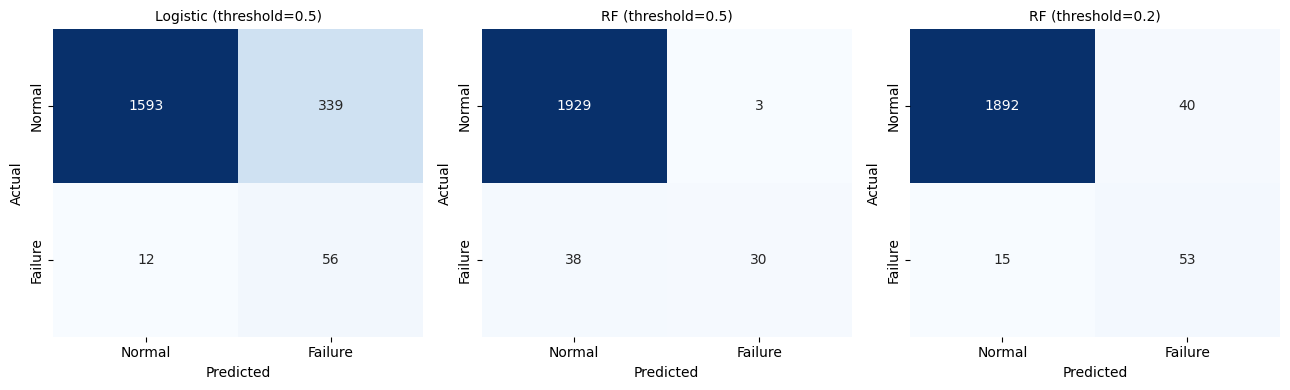

In [17]:

# 5. Evaluation - Confusion Matrix Visualization

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("artifacts/figures", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (label, matrix) in zip(
    axes, confusion_matrices.items()
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Normal", "Failure"],
        yticklabels=["Normal", "Failure"],
        ax=ax
    )

    short_name = label.replace(
        "Logistic Regression", "Logistic"
    ).replace("Random Forest", "RF")

    ax.set_title(short_name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.savefig(
    "artifacts/figures/confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



### Confusion Matrix Comparison Findings

The confusion matrices show the trade-off between detecting failures and generating false alarms.

- Logistic Regression detected 56 failures but generated 339 false alarms.
- Random Forest with the default threshold of 0.5 detected 30 failures and missed 38.
- Random Forest with a threshold of 0.2 detected 53 failures, missed 15, and generated 40 false alarms.

Random Forest with a threshold of 0.2 achieved the highest test F1-score among the evaluated configurations.

This result supports its selection for the educational demonstration. However, the best threshold for real maintenance operations would depend on the costs of missed failures and unnecessary inspections.


In [18]:

# 5. Evaluation - Naive Baseline Comparison

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Naive baseline: predict every machine as normal.
baseline_predictions = np.zeros(len(y_test), dtype=int)

# Selected Random Forest model, threshold = 0.2.
rf_probabilities = trained_models[
    "Random Forest"
].predict_proba(X_test)[:, 1]

rf_predictions = (rf_probabilities >= 0.2).astype(int)

print("Naive Baseline vs Selected Random Forest")
print("--------------------------------------")

for name, predictions in [
    ("Always Normal", baseline_predictions),
    ("Random Forest (0.2)", rf_predictions)
]:
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    print(f"\n{name}")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")


Naive Baseline vs Selected Random Forest
--------------------------------------

Always Normal
Accuracy:  0.9660
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Random Forest (0.2)
Accuracy:  0.9725
Precision: 0.5699
Recall:    0.7794
F1-score:  0.6584



### Naive Baseline Comparison Findings

An always-normal baseline was compared with the selected Random Forest model on the held-out test set.

The always-normal baseline achieved 96.60% accuracy but had zero precision, recall, and F1-score because it did not detect any machine failures.

Random Forest with a threshold of 0.2 achieved:
- Accuracy: 97.25%
- Precision: 56.99%
- Recall: 77.94%
- F1-score: 65.84%

The selected Random Forest detected 53 of the 68 actual failures, while the always-normal baseline detected none.

This comparison demonstrates why accuracy alone is misleading for imbalanced failure classification.

Although Random Forest performed better than the naive baseline, the results are based on synthetic data and do not establish real-world reliability.



## 6. Deployment

This phase demonstrates how the trained model can be reused for machine failure prediction.

The selected Random Forest model uses a classification threshold of 0.2.

The deployment demonstration includes:
1. Saving the trained model and its preprocessing pipeline.
2. Loading the saved model.
3. Predicting a machine failure probability from operating conditions.
4. Generating an alert when the predicted probability reaches the selected threshold.

This is an educational prototype, not a production deployment. Real-world deployment would require additional validation, monitoring, and integration with industrial equipment.


In [19]:

# 6. Deployment - Save and Load Model

import joblib
import os

os.makedirs("artifacts/models", exist_ok=True)

model_path = "artifacts/models/random_forest_model.joblib"

# Save the fitted preprocessing and model pipeline.
joblib.dump(
    trained_models["Random Forest"],
    model_path
)

# Load the saved model.
loaded_model = joblib.load(model_path)

print("Model saved successfully.")
print("Model loaded successfully.")
print("File:", model_path)
print("Selected threshold: 0.2")


Model saved successfully.
Model loaded successfully.
File: artifacts/models/random_forest_model.joblib
Selected threshold: 0.2


In [20]:

# 6. Deployment - Prediction Demonstration

import pandas as pd

# Example operating conditions (illustrative inputs).
new_machine = pd.DataFrame([{
    "Air temperature [K]": 300.0,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1400,
    "Torque [Nm]": 50.0,
    "Tool wear [min]": 180,
    "Type": "L"
}])

selected_threshold = 0.2

failure_probability = loaded_model.predict_proba(
    new_machine
)[0, 1]

prediction = int(
    failure_probability >= selected_threshold
)

print("Machine Failure Prediction")
print("--------------------------")
print(f"Failure probability: {failure_probability:.4f}")
print(f"Threshold: {selected_threshold:.2f}")

if prediction == 1:
    print("Result: WARNING - Potential machine failure")
else:
    print("Result: NORMAL - No failure alert")


Machine Failure Prediction
--------------------------
Failure probability: 0.0050
Threshold: 0.20
Result: NORMAL - No failure alert



### Deployment Demonstration Results

The trained Random Forest pipeline was saved and successfully loaded using joblib.

For the illustrative machine input, the model produced a failure score of 0.0050.

Since this score was below the selected threshold of 0.2, the system returned a NORMAL result.

This demonstrates that the saved model can process new operating measurements and generate a classification result.

The output is a model score rather than a calibrated real-world failure probability. The prototype requires further validation before industrial use.


In [21]:

# 6. Deployment - Model Persistence Validation

import numpy as np

original_model = trained_models["Random Forest"]

# Compare predictions before and after saving.
original_scores = original_model.predict_proba(
    X_test
)[:, 1]

loaded_scores = loaded_model.predict_proba(
    X_test
)[:, 1]

scores_match = np.allclose(
    original_scores,
    loaded_scores,
    rtol=0,
    atol=1e-12
)

print("Model Persistence Validation")
print("----------------------------")
print("Test samples checked:", len(X_test))
print("Prediction scores match:", scores_match)

assert scores_match, "Saved model predictions do not match."

print("PASS: Saved and loaded models give matching predictions.")


Model Persistence Validation
----------------------------
Test samples checked: 2000
Prediction scores match: True
PASS: Saved and loaded models give matching predictions.



### Model Persistence Validation Findings

The saved Random Forest pipeline was loaded successfully.

Predictions from the original and loaded models were compared using 2,000 test samples.

The prediction scores matched within a numerical tolerance of 1e-12.

This confirms that saving and loading the model preserved its prediction behavior in the current environment.

The validation does not establish compatibility across different software environments or readiness for industrial deployment.


In [22]:

# 6. Deployment - Input Validation

import pandas as pd
import numpy as np

def validate_machine_input(machine_data):
    required_columns = [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Type"
    ]

    # Check required columns.
    missing = [
        col for col in required_columns
        if col not in machine_data.columns
    ]

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    # Check numeric inputs.
    numeric_columns = required_columns[:-1]

    for col in numeric_columns:
        values = pd.to_numeric(
            machine_data[col], errors="coerce"
        )

        if not np.isfinite(values.to_numpy(dtype=float)).all():
            raise ValueError(f"Invalid numeric values: {col}")

    # Check product type.
    allowed_types = {"L", "M", "H"}

    if not machine_data["Type"].isin(allowed_types).all():
        raise ValueError("Invalid product type.")

    # Tool wear time cannot be negative.
    if (machine_data["Tool wear [min]"] < 0).any():
        raise ValueError("Tool wear cannot be negative.")

    return True


# Test valid input.
print("Valid input test:")
print("PASS" if validate_machine_input(new_machine) else "FAIL")

# Test invalid input.
invalid_machine = new_machine.copy()
invalid_machine["Tool wear [min]"] = -5

print("\nInvalid input test:")

try:
    validate_machine_input(invalid_machine)
    print("FAIL: Invalid input was accepted.")
except ValueError as error:
    print("PASS: Invalid input rejected.")
    print("Reason:", error)


Valid input test:
PASS

Invalid input test:
PASS: Invalid input rejected.
Reason: Tool wear cannot be negative.



### Input Validation Findings

Basic input validation was added to the deployment prototype.

The validation checks:
- Whether all required input columns are present.
- Whether numeric inputs contain valid finite values.
- Whether product type is L, M, or H.
- Whether tool wear time is non-negative.

The tests produced the following results:

- Valid input: PASS
- Invalid input with negative tool wear: PASS (rejected)
- Rejection reason: Tool wear cannot be negative.

These tests confirm that the validation function accepts the example valid input and rejects a negative tool wear value.

However, this is a basic validation demonstration. It does not cover all invalid input cases, enforce all physical sensor ranges, or establish production readiness.

The validation function is demonstrated separately from the prediction workflow.


In [23]:

# 6. Deployment - Validated Prediction

def predict_machine_failure(machine_data, model, threshold=0.2):
    # Validate input before making predictions.
    validate_machine_input(machine_data)

    # Use the saved preprocessing and classification pipeline.
    scores = model.predict_proba(machine_data)[:, 1]
    predictions = (scores >= threshold).astype(int)

    return pd.DataFrame({
        "Failure score": scores,
        "Prediction": np.where(
            predictions == 1, "FAILURE", "NORMAL"
        )
    })


# Use the previously reloaded Random Forest pipeline.
print("Valid input prediction:")
display(
    predict_machine_failure(
        new_machine,
        loaded_model,
        threshold=0.2
    )
)

# Confirm invalid input is rejected before prediction.
print("\nInvalid input prediction test:")

try:
    predict_machine_failure(
        invalid_machine,
        loaded_model,
        threshold=0.2
    )
    print("FAIL: Invalid input was accepted.")
except ValueError as error:
    print("PASS: Invalid input rejected before prediction.")
    print("Reason:", error)


Valid input prediction:


,Failure score,Prediction
0,0.005,NORMAL



Invalid input prediction test:
PASS: Invalid input rejected before prediction.
Reason: Tool wear cannot be negative.



### Validated Prediction Findings

The input validation function was integrated into the prediction workflow.

For the valid example:
- Failure score: 0.0050
- Prediction: NORMAL
- Classification threshold: 0.2

For the invalid example:
- Input: Negative tool wear (-5)
- Result: Rejected before prediction
- Validation test: PASS

This confirms that the demonstration prediction function checks inputs before passing them to the trained Random Forest pipeline.

The failure score is a model output and should not be interpreted as a calibrated real-world failure probability.

The prototype remains an educational demonstration and is not intended for production use.
